# Syllables and neuromodulators: effects, not just correlations

New analyses of what each neuromodulator's photometry signal tracks in behaviour. Built on `Functions/nm_syllables.py`, which reads only the photometry export (`pose_qc_hmm_k4`) and the 30 Hz states files. Notebooks 4–6 still use the older `event_psth.py` / `syllable_photometry.py`; this notebook does not.

**Plan**
0. **Loader, checked**: reproduce notebook 6's cached raw correlation maps.
1. **Effect sizes** instead of r: Δz and partial β, next to each feature's base rate, so the maps stop tracking how common a syllable is.
2. **Joint model**: all features at once.
3. **Syllable identity vs continuous vigor** (paw speed, wheel speed, whisker ME, licks).
4. **Across mice**: everything above on the full export, mice as the unit.
5. **Trial position**: is the slow change over the session engagement, or something else?
6. *(next)* Syllable-onset responses by context, and an encoding model with task-event and movement kernels.

Sections 1–3 show one example fiber, to explain each quantity. Section 4 is the result. The full run is `python neuromodulators/run_nm_syllable_effects.py` (~1 min on 10 cores); it caches every table that section 4 reads.

CCA and reduced-rank regression on whole-trial shapes are in `8_nm_trial_shapes.ipynb`.

In [1]:
import sys, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'nm_syllables.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
from Functions import nm_syllables as ns
for msg in ['Mean of empty slice', 'Degrees of freedom', 'invalid value encountered', 'divide by zero', 'Precision loss']:
    warnings.filterwarnings('ignore', message=msg)

CACHE = ns.DATA / 'syllables_photometry'
NM_ORDER = ['DR-5HT', 'VTA-DA', 'SNc-DA', 'LC-NE', 'NBM-ACh']
rec = ns.load_recordings()
print(f'{len(rec)} fibers in {rec["eid"].nunique()} sessions from {rec["subject"].nunique()} mice '
      f'(states file covering ≥ {ns.MIN_COVERAGE:.0%} of the session)')
rec.groupby('target_NM').agg(fibers=('eid', 'size'), sessions=('eid', 'nunique'), mice=('subject', 'nunique')).loc[NM_ORDER]

516 fibers in 489 sessions from 36 mice (states file covering ≥ 25% of the session)


,fibers,sessions,mice
target_NM,,,
DR-5HT,140,140,9
VTA-DA,140,140,7
SNc-DA,65,65,6
LC-NE,96,96,8
NBM-ACh,75,50,7


## 0. The loader reproduces notebook 6

The cached maps were pickled under numpy 2. The shim below lets numpy 1.x read them. For 25 random sessions, raw r maps are recomputed (factored features: 8 paw states, whisking, licking), and their Fisher z is compared with `corr_factored_raw`. They should agree to float32 precision, with the same blank samples.

In [2]:
def read_numpy2_pickle(path):
    try:
        import numpy._core.numeric  # noqa: F401  (numpy >= 2)
    except ImportError:
        for m in ['', '.numeric', '.multiarray', '._multiarray_umath']:
            sys.modules['numpy._core' + m] = __import__('numpy.core' + m, fromlist=['x'])
    return pd.read_pickle(path)

cached = read_numpy2_pickle(CACHE / f'corr_factored_raw_{ns.RUN}.pkl')
CHECK = np.random.default_rng(0).choice(rec['eid'].unique(), 25, replace=False)
FIBERS = {eid: ns.load_session(eid) for eid in CHECK}
rows = []
for eid, fibers in FIBERS.items():
    for fiber in fibers:
        new = ns.correlation_maps(fiber)
        for _, r in new.iterrows():
            old = cached[(cached['eid'] == eid) & (cached['region'] == r['region']) & (cached['outcome'] == r['outcome'])]
            if old.empty:
                continue
            old = old.iloc[0]
            for w in ['z_stim', 'z_fb']:
                rows.append({'eid': eid[:8], 'region': r['region'], 'outcome': r['outcome'], 'window': w[2:],
                             'n_trials': (r['n_trials'], old['n_trials']),
                             'same blanks': bool((np.isnan(r[w]) == np.isnan(old[w])).all()),
                             'max |Δz|': np.nanmax(np.abs(r[w] - old[w])), 'valid cells': int((~np.isnan(r[w])).sum())})
check = pd.DataFrame(rows)
print(f"{check['eid'].nunique()} sessions, {len(check)} maps: n_trials equal in all: "
      f"{all(a == b for a, b in check['n_trials'])}, same blanks in all: {check['same blanks'].all()}, "
      f"max |Δz| = {check['max |Δz|'].max():.1e}")

25 sessions, 116 maps: n_trials equal in all: True, same blanks in all: True, max |Δz| = 1.7e-08


## Sessions whose states file stops early

The design matrix (`segmentation/1_camera_setup/2.1.1_design_matrix.ipynb`) is cut to the time span shared by camera, wheel and licks, so a short video shortens the states file. Coverage = fraction of the session's trials that fall inside the file. Two sessions are short, both because of the video:

- **813e8682** (ZFM-08828, VTA-DA, 2025-10-06): the camera recorded only 11 142 frames (6 of the 83 min; `frameData.bin` has the same count), so nothing more exists. Coverage .07 → **dropped** (below `ns.MIN_COVERAGE` = .25).
- **e637617d** (ZFM-04392, DR-5HT, 2023-02-03): the mp4 has all 155 709 frames, but camera times, Lightning Pose and motion energy were extracted for only the first 61 901 (video QC: `camera_times` WARNING with 93 808 missing, `pin_state` FAIL). Coverage .40 → kept, with the first 413 trials. **Recoverable** by re-extracting the camera timestamps and rerunning LP and ME on the full video.

Every other session covers ≥ .99.

In [3]:
cov = ns.states_coverage()
print(cov['coverage'].describe().round(3).to_string())
cov.sort_values('coverage').head(4)

count    490.000
mean       0.995
std        0.050
min        0.072
25%        0.997
50%        0.998
75%        0.998
max        0.999


,subject,first_bin,last_bin,session_start,session_end,n_trials,coverage
eid,,,,,,,
813e8682-99dd-4642-b098-f1a12f2205cb,ZFM-08828,55.431400,424.931400,53.8392,4960.032001,1186.0,0.071669
e637617d-4ef5-403e-9f3d-14cac9599e02,ZFM-04392,4.655133,2063.355133,0.0000,5169.371800,1044.0,0.395594
092d99c6-6892-47e1-8958-2f48e234a1d4,ZFM-09139,118.346367,3069.013033,117.6872,3069.368801,243.0,0.991770
acd6de19-bc14-46cc-9efc-27227ded4d36,ZFM-09365,36.217667,3062.051000,33.7589,3064.371601,282.0,0.992908


## 1. Effect sizes instead of r

For a 0/1 feature, r = Δz / sd(z) · √(p(1−p)). Here Δz is the difference in mean photometry between trials with and without the feature, and p is the feature's base rate at that sample. So r shrinks wherever a feature is very common or very rare, even when its effect on the signal is unchanged. `ns.effect_maps` keeps the pieces apart. Each one is computed per fiber-session, outcome, window, feature and sample:

| | |
|---|---|
| `p` | base rate: the fraction of trials in the feature |
| `r` | point-biserial r, as in notebook 6 |
| `dz` | Δz, in z-scored GCaMP units. It does not depend on p |
| `d` | Δz / sd(z) = r / √(p(1−p)): r with the base rate taken out |
| `beta`, `t` | Δz with covariates held fixed (OLS). `task` = log response RT, \|contrast\| level, trial position and position² (notebook 6's set). `extended` adds previous outcome, choice side and block congruence |

A sample is kept only with ≥ 20 trials and ≥ 5 on each side of the feature, as before.

DR-5HT ZFM-09365 · rewarded trials (957 with syllables at most)


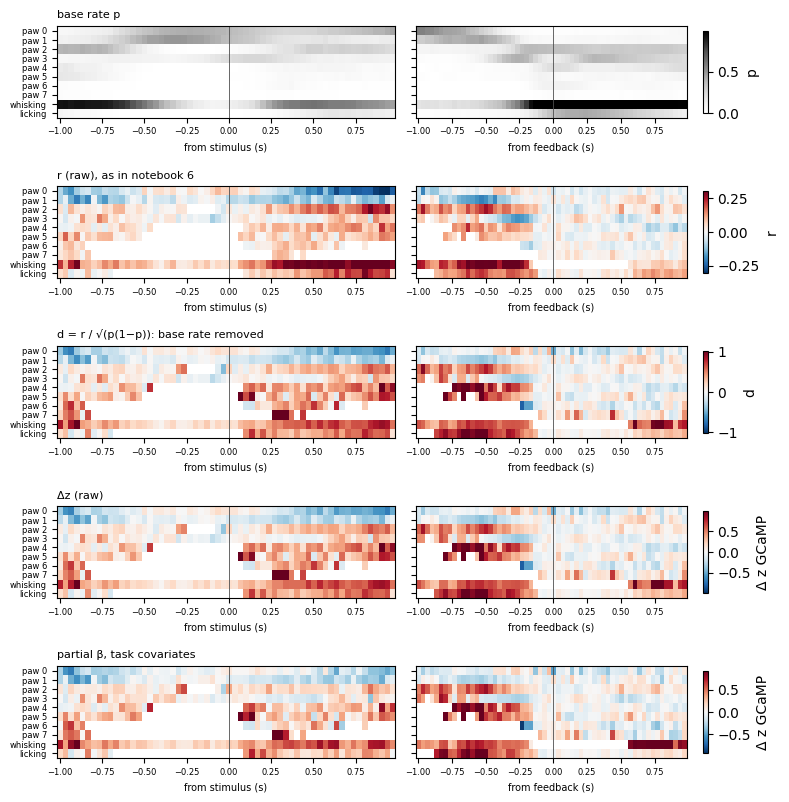

In [4]:
PAL = ns.load_palette()
# example: the DR-5HT fiber with the most trials (whisking is the most consistent effect for 5HT)
EX = rec[rec['target_NM'] == 'DR-5HT'].merge(cov[['n_trials']], left_on='eid', right_index=True).sort_values('n_trials').iloc[-1]
FIBER = next(f for f in ns.load_session(EX['eid']) if f['region'] == EX['brain_region'])
EM = {cov: ns.effect_maps(FIBER, covariates=cov) for cov in ('task', 'extended')}
NAMES = EM['task'].attrs['features']
TIME = FIBER['time']

def map_pair(fig, spec, A, title, cmap='RdBu_r', lim=None, cbar_label=''):
    # one row: stimulus-aligned | feedback-aligned map of an (F x T) pair, shared colour scale
    lim = lim if lim is not None else np.nanpercentile(np.abs(np.concatenate([a.ravel() for a in A])), 98)
    vmin = 0 if cmap != 'RdBu_r' else -lim
    sub = spec.subgridspec(1, 2, wspace=0.06)
    h = (TIME[1] - TIME[0]) / 2
    for k, (a, lab) in enumerate(zip(A, ['from stimulus (s)', 'from feedback (s)'])):
        ax = fig.add_subplot(sub[k])
        im = ax.imshow(a, aspect='auto', cmap=cmap, vmin=vmin, vmax=lim, interpolation='nearest',
                       extent=(TIME[0] - h, TIME[-1] + h, len(a) - 0.5, -0.5))
        ax.axvline(0, color='0.3', lw=0.6)
        ax.set_yticks(range(len(NAMES)), NAMES if k == 0 else [], fontsize=6)
        ax.set_xlabel(lab, fontsize=7); ax.tick_params(labelsize=6)
        if k == 0:
            ax.set_title(title, fontsize=8, loc='left')
    fig.colorbar(im, ax=ax, shrink=0.9, label=cbar_label)

def effect_figure(row, metrics):
    fig = plt.figure(figsize=(9, 1.9 * len(metrics)))
    gs = fig.add_gridspec(len(metrics), 1, hspace=0.75)
    for i, (col, title, cmap, label) in enumerate(metrics):
        map_pair(fig, gs[i], [row[f'{col}_stim'], row[f'{col}_fb']], title, cmap=cmap, cbar_label=label)
    plt.show()

METRICS = [('p', 'base rate p', 'Greys', 'p'), ('r', 'r (raw), as in notebook 6', 'RdBu_r', 'r'),
           ('d', 'd = r / √(p(1−p)): base rate removed', 'RdBu_r', 'd'),
           ('dz', 'Δz (raw)', 'RdBu_r', 'Δ z GCaMP'), ('beta', 'partial β, task covariates', 'RdBu_r', 'Δ z GCaMP')]
row = EM['task'].query('outcome == 1').iloc[0]
print(f"{row['target_NM']} {row['subject']} · rewarded trials ({int(np.nanmax(row['n_stim']))} with syllables at most)")
effect_figure(row, METRICS)

### Where r and d disagree

The same three features (still paw, whisking, licking) over time, on rewarded trials. Each panel shows the base rate on the right axis (grey) and r, d and β on the left. Where p is near 0 or 1, r is pulled toward 0 even when d and β are not.

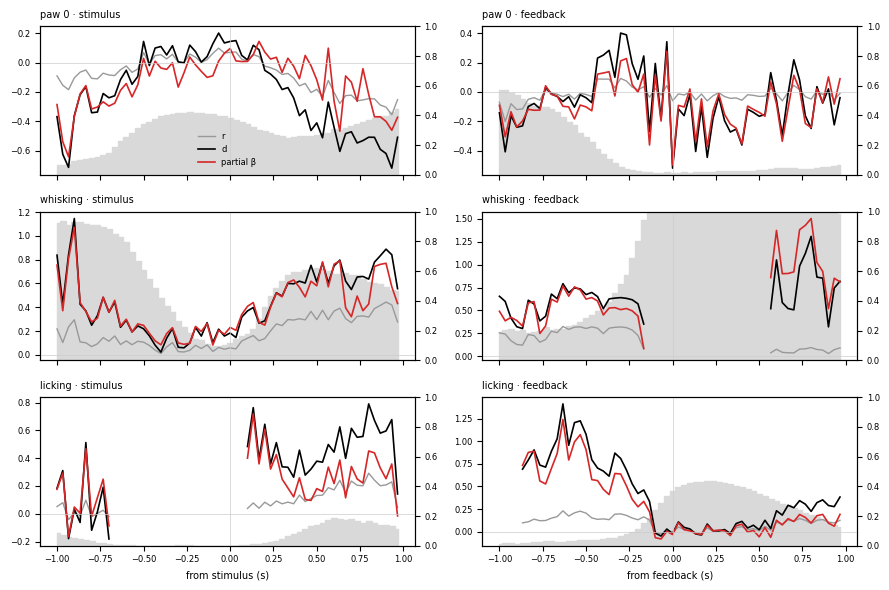

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(9, 6), sharex='col')
for i, feat in enumerate(['paw 0', 'whisking', 'licking']):
    fi = NAMES.index(feat)
    for k, w in enumerate(ns.WINDOWS):
        ax = axes[i, k]
        ax.plot(TIME, row[f'r_{w}'][fi], color='0.6', lw=1, label='r')
        ax.plot(TIME, row[f'd_{w}'][fi], color='k', lw=1.2, label='d')
        ax.plot(TIME, row[f'beta_{w}'][fi], color='C3', lw=1.2, label='partial β')
        ax.axhline(0, color='0.8', lw=0.5); ax.axvline(0, color='0.8', lw=0.5)
        ax2 = ax.twinx(); ax2.fill_between(TIME, 0, row[f'p_{w}'][fi], color='0.85', step='mid', zorder=0)
        ax2.set_ylim(0, 1); ax2.tick_params(labelsize=6)
        ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
        ax.set_title(f'{feat} · {"stimulus" if w == "stim" else "feedback"}', fontsize=7, loc='left')
        ax.tick_params(labelsize=6)
axes[0, 0].legend(fontsize=6, frameon=False)
for ax, lab in zip(axes[-1], ['from stimulus (s)', 'from feedback (s)']):
    ax.set_xlabel(lab, fontsize=7)
plt.tight_layout(); plt.show()

### Syllable vs photometry, one dot per sample

The simplest view. Each dot is one sample: one trial at one timestep, in the stimulus window (blue) or the feedback window (orange). Every unmasked sample with a syllable code is shown, with no minimum number of trials. x is whether the trial is in that feature at that timestep (0 or 1, jittered so the dots spread out). y is the z-scored GCaMP of that trial at that timestep. The line is a least-squares fit over all dots. Its slope is the pooled Δz (mean signal with the feature minus without), and r is the pooled point-biserial correlation, as in notebook 6's "pooled over all samples".

This mixes the time-course relation (a feature and the signal both following the trial's structure, like licking and the reward response) with the trial-to-trial one. Samples from the same trial are not independent, so r describes the plot; it is not a test.

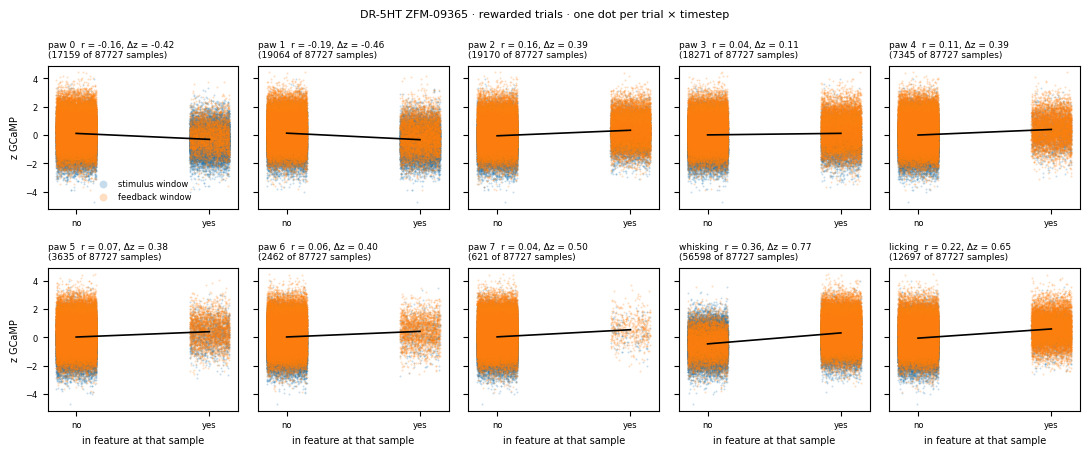

In [6]:
def sample_points(fiber, outcome, features=ns.factored_features):
    # one row per (trial, timestep, window) with a photometry value and a syllable code
    idx = fiber['meta'].index[fiber['meta']['correct'] == outcome].to_numpy()
    pts = []
    for w in ns.WINDOWS:
        P = fiber[w]['photometry'][idx]
        names, F = features(fiber[w]['code'][idx])
        ok = ~np.isnan(P) & ~np.isnan(F[0])
        trial, step = np.nonzero(ok)
        pts.append(pd.DataFrame({'window': w, 'trial': idx[trial], 'time': TIME[step], 'z': P[ok],
                                 **{name: F[k][ok] for k, name in enumerate(names)}}))
    return names, pd.concat(pts, ignore_index=True)

names, pts = sample_points(FIBER, outcome=1)
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 5, figsize=(11, 4.6), sharey=True)
for ax, name in zip(axes.flat, names):
    jitter = rng.uniform(-0.15, 0.15, len(pts))
    for w, c in zip(ns.WINDOWS, ['C0', 'C1']):
        m = (pts['window'] == w).to_numpy()
        ax.scatter(pts.loc[m, name] + jitter[m], pts.loc[m, 'z'], s=2, color=c, alpha=0.25, lw=0,
                   label={'stim': 'stimulus window', 'fb': 'feedback window'}[w])
    title = f"{name}  ({int(pts[name].sum())} of {len(pts)} samples)"
    if pts[name].nunique() > 1:
        b = np.polyfit(pts[name], pts['z'], 1)
        ax.plot([0, 1], np.polyval(b, [0, 1]), color='k', lw=1.2)
        title = f"{name}  r = {np.corrcoef(pts[name], pts['z'])[0, 1]:.2f}, Δz = {b[0]:.2f}\n({int(pts[name].sum())} of {len(pts)} samples)"
    ax.set_title(title, fontsize=6.5, loc='left')
    ax.set_xticks([0, 1], ['no', 'yes'], fontsize=6); ax.tick_params(labelsize=6)
for ax in axes[-1]:
    ax.set_xlabel('in feature at that sample', fontsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel('z GCaMP', fontsize=7)
axes[0, 0].legend(fontsize=6, frameon=False, markerscale=4)
fig.suptitle(f"{FIBER['meta']['target_NM'].iat[0]} {FIBER['meta']['subject'].iat[0]} · rewarded trials · one dot per trial × timestep", fontsize=8)
plt.tight_layout(); plt.show()

### Continuous movement vs photometry, one dot per sample

The same plot, but on the continuous signals the syllables were built from. x is now a real quantity:
- **paw speed**: left-paw speed from the pose x/y, in px/s, shown as log10(1 + ·);
- **wheel speed**: |wheel velocity|, shown as log10(1 + ·);
- **whisker ME**: whisker-pad motion energy, in raw units;
- **lick rate**: licks/s. `Lick count` is a 0/1 lick event per 30 Hz bin, so it is counted over a centred ~233 ms window (`ns.LICK_WINDOW`).

Each dot is one trial at one timestep (blue: stimulus window, orange: feedback window). The line is a least-squares fit over all dots, and r is their correlation. The same caveats apply: it mixes timing with trial-to-trial variation, and samples within a trial are not independent.

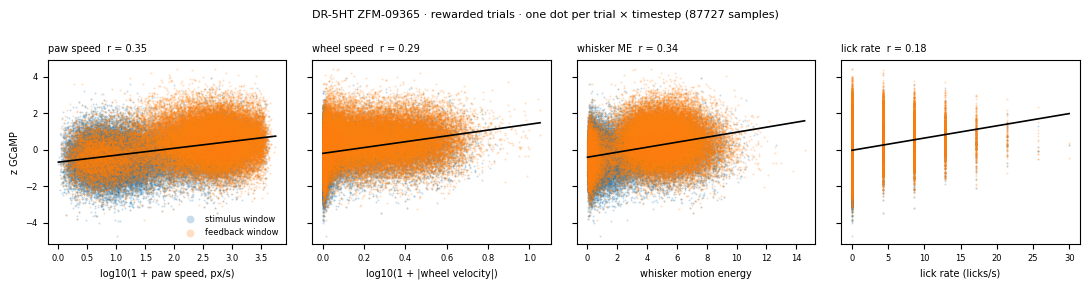

In [7]:
SIGNALS = [('paw speed', 'log10(1 + paw speed, px/s)', np.log10), ('wheel speed', 'log10(1 + |wheel velocity|)', np.log10),
           ('whisker ME', 'whisker motion energy', None), ('lick rate', 'lick rate (licks/s)', None)]

def movement_points(fiber, outcome):
    idx = fiber['meta'].index[fiber['meta']['correct'] == outcome].to_numpy()
    pts = []
    for w in ns.WINDOWS:
        P, M = fiber[w]['photometry'][idx], fiber[w]['movement']
        ok = ~np.isnan(P) & np.all([~np.isnan(M[s][idx]) for s, _, _ in SIGNALS], axis=0)
        pts.append(pd.DataFrame({'window': w, 'z': P[ok], **{s: M[s][idx][ok] for s, _, _ in SIGNALS}}))
    return pd.concat(pts, ignore_index=True)

mp = movement_points(FIBER, outcome=1)
fig, axes = plt.subplots(1, 4, figsize=(11, 2.9), sharey=True)
for ax, (s, label, f) in zip(axes, SIGNALS):
    x = f(1 + mp[s]) if f is not None else mp[s]
    for w, c in zip(ns.WINDOWS, ['C0', 'C1']):
        m = (mp['window'] == w).to_numpy()
        ax.scatter(x[m], mp.loc[m, 'z'], s=2, color=c, alpha=0.25, lw=0,
                   label={'stim': 'stimulus window', 'fb': 'feedback window'}[w])
    b = np.polyfit(x, mp['z'], 1)
    xs = np.array([x.min(), x.max()])
    ax.plot(xs, np.polyval(b, xs), color='k', lw=1.2)
    ax.set_title(f'{s}  r = {np.corrcoef(x, mp["z"])[0, 1]:.2f}', fontsize=7, loc='left')
    ax.set_xlabel(label, fontsize=7); ax.tick_params(labelsize=6)
axes[0].set_ylabel('z GCaMP', fontsize=7)
axes[0].legend(fontsize=6, frameon=False, markerscale=4)
fig.suptitle(f"{FIBER['meta']['target_NM'].iat[0]} {FIBER['meta']['subject'].iat[0]} · rewarded trials · "
             f"one dot per trial × timestep ({len(mp)} samples)", fontsize=8)
plt.tight_layout(); plt.show()

### Extended covariates

Here β also holds fixed previous outcome, choice side and block congruence. These are the obvious task drivers of dopamine besides movement. The map shows how much of the task-covariate β they take away (task β − extended β, same colour scale as β).

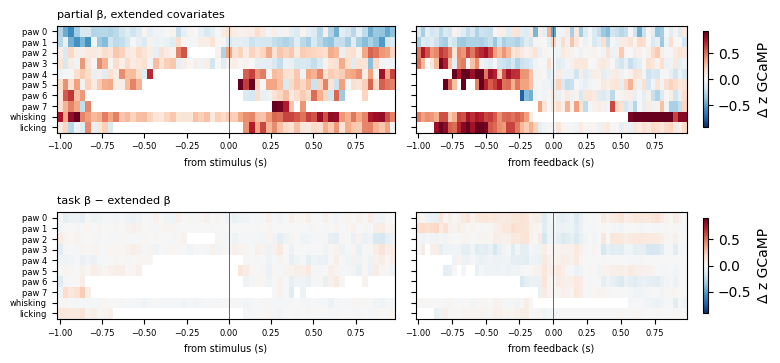

In [8]:
rx = EM['extended'].query('outcome == 1').iloc[0]
fig = plt.figure(figsize=(9, 3.8)); gs = fig.add_gridspec(2, 1, hspace=0.75)
lim = np.nanpercentile(np.abs(np.concatenate([row['beta_stim'].ravel(), row['beta_fb'].ravel()])), 98)
map_pair(fig, gs[0], [rx['beta_stim'], rx['beta_fb']], 'partial β, extended covariates', lim=lim, cbar_label='Δ z GCaMP')
map_pair(fig, gs[1], [row['beta_stim'] - rx['beta_stim'], row['beta_fb'] - rx['beta_fb']], 'task β − extended β',
         lim=lim, cbar_label='Δ z GCaMP')
plt.show()

## 2. Joint model: each feature's unique effect

The marginal maps above test one feature at a time. But the features overlap: the paw states sum to 1, and whisking goes with the active paw states. `ns.joint_maps` puts them all in one regression per sample: paw states 1–7 against paw 0 (stillest), plus whisking, licking and the task covariates. A feature rarer than 5 trials at a sample is left out of that sample's model. The β of whisking is now its effect at a fixed paw state, and the reverse for the paw states.

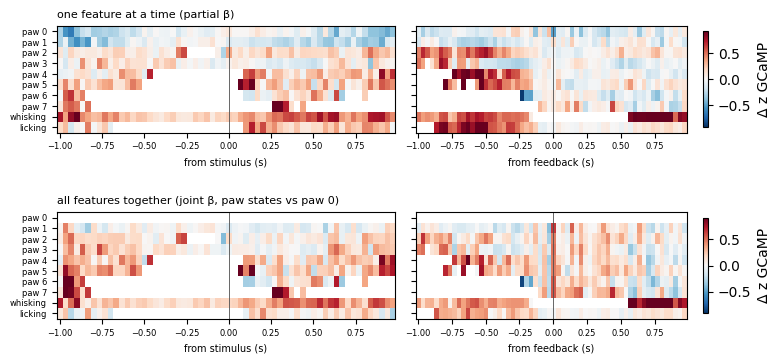

In [9]:
JM = ns.joint_maps(FIBER)
jr = JM.query('outcome == 1').iloc[0]
fig = plt.figure(figsize=(9, 3.8)); gs = fig.add_gridspec(2, 1, hspace=0.75)
lim = np.nanpercentile(np.abs(np.concatenate([row['beta_stim'].ravel(), row['beta_fb'].ravel()])), 98)
map_pair(fig, gs[0], [row['beta_stim'], row['beta_fb']], 'one feature at a time (partial β)', lim=lim, cbar_label='Δ z GCaMP')
map_pair(fig, gs[1], [jr['beta_stim'], jr['beta_fb']], 'all features together (joint β, paw states vs paw 0)', lim=lim,
         cbar_label='Δ z GCaMP')
plt.show()

## 3. Syllable identity vs continuous vigor

Does the NM track *which* syllable the mouse is in, or just *how much* it moves? At each sample, four nested ridge models of the photometry are fitted (standardised predictors) and scored by 5-fold cross-validated R² across trials:
1. task variables only (log response RT, |contrast| level, trial position and position²);
2. \+ vigor: log(1 + ·) of paw speed, wheel speed, whisker motion energy and lick rate at that sample;
3. \+ syllables: the factored one-hots;
4. \+ both.

Unique syllable variance = R²(4) − R²(2). Unique vigor variance = R²(4) − R²(3).

The ridge penalty is chosen on each training fold by leave-one-out error (`alpha='auto'`, 0.1 to 10⁵). With a fixed α = 1, every model scored below zero even on full sessions: the effects explain ~1% of the variance at a sample, less than the cost of fitting ~20 predictors. With the penalty chosen per fold, a model that adds nothing shrinks to the smaller model and its unique R² goes to ~0 instead.

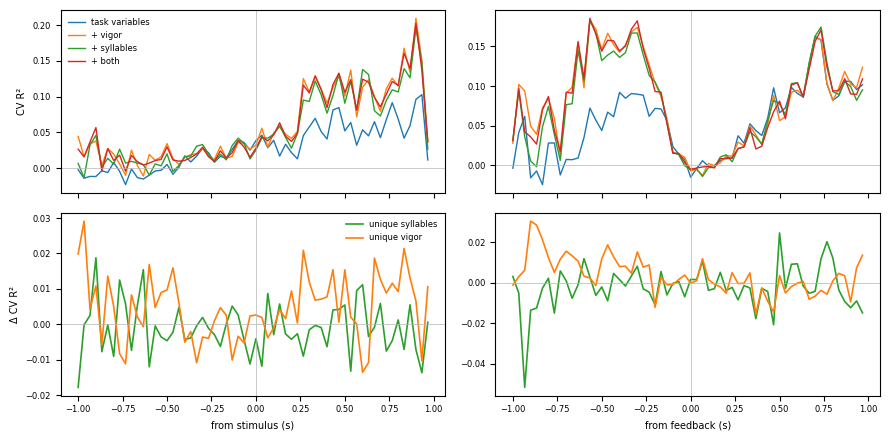

In [10]:
VP = ns.variance_partition(FIBER)
vr = VP.query('outcome == 1').iloc[0]
fig, axes = plt.subplots(2, 2, figsize=(9, 4.5), sharex='col')
for k, w in enumerate(ns.WINDOWS):
    R = vr[f'r2_{w}']
    for m, name in enumerate(VP.attrs['models']):
        axes[0, k].plot(TIME, R[m], lw=1, label=name)
    axes[1, k].plot(TIME, R[3] - R[1], color='C2', lw=1.2, label='unique syllables')
    axes[1, k].plot(TIME, R[3] - R[2], color='C1', lw=1.2, label='unique vigor')
    for ax in axes[:, k]:
        ax.axhline(0, color='0.7', lw=0.5); ax.axvline(0, color='0.7', lw=0.5); ax.tick_params(labelsize=6)
    axes[1, k].set_xlabel(['from stimulus (s)', 'from feedback (s)'][k], fontsize=7)
axes[0, 0].set_ylabel('CV R²', fontsize=7); axes[1, 0].set_ylabel('Δ CV R²', fontsize=7)
axes[0, 0].legend(fontsize=6, frameon=False); axes[1, 0].legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()

## 4. Across mice

Every analysis above, on every fiber (`run_nm_syllable_effects.py`). Each fiber-session gives one map per outcome. A mouse's maps are averaged over its sessions, and the mice are the unit (`ns.summarise`: t-test across mice, FDR over the map).

### 4a. Partial β maps (task covariates)

The effect of each feature on the photometry, in z units, with log RT, contrast and trial position held fixed. Dots: FDR q < 0.05 across mice.

{'task': 1032, 'extended': 1032, 'joint': 1032, 'variance': 1032} fiber-session × outcome rows


/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(mice, 0, axis=0, nan_policy='omit')
/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(mice, 0, axis=0, nan_policy='omit')
/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation f

/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(mice, 0, axis=0, nan_policy='omit')
/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(mice, 0, axis=0, nan_policy='omit')
/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation f

/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(mice, 0, axis=0, nan_policy='omit')
/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(mice, 0, axis=0, nan_policy='omit')
/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation f

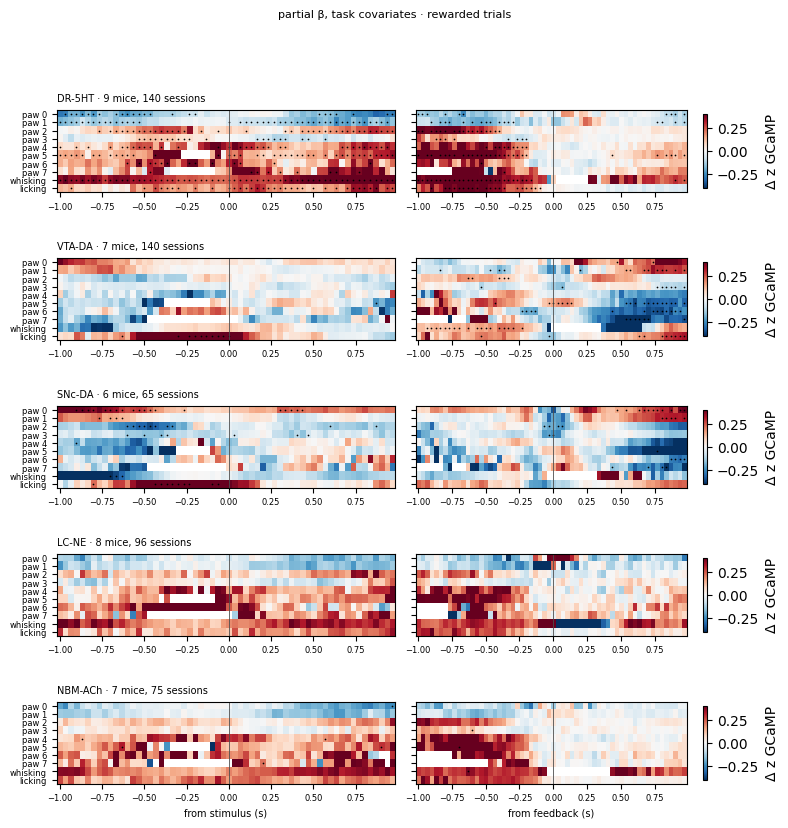

/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(mice, 0, axis=0, nan_policy='omit')
/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(mice, 0, axis=0, nan_policy='omit')
/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation f

/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(mice, 0, axis=0, nan_policy='omit')
/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(mice, 0, axis=0, nan_policy='omit')
/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation f

/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(mice, 0, axis=0, nan_policy='omit')
/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  t, p = ttest_1samp(mice, 0, axis=0, nan_policy='omit')
/home/ines/repositories/representation_learning_variability/Functions/nm_syllables.py:705: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation f

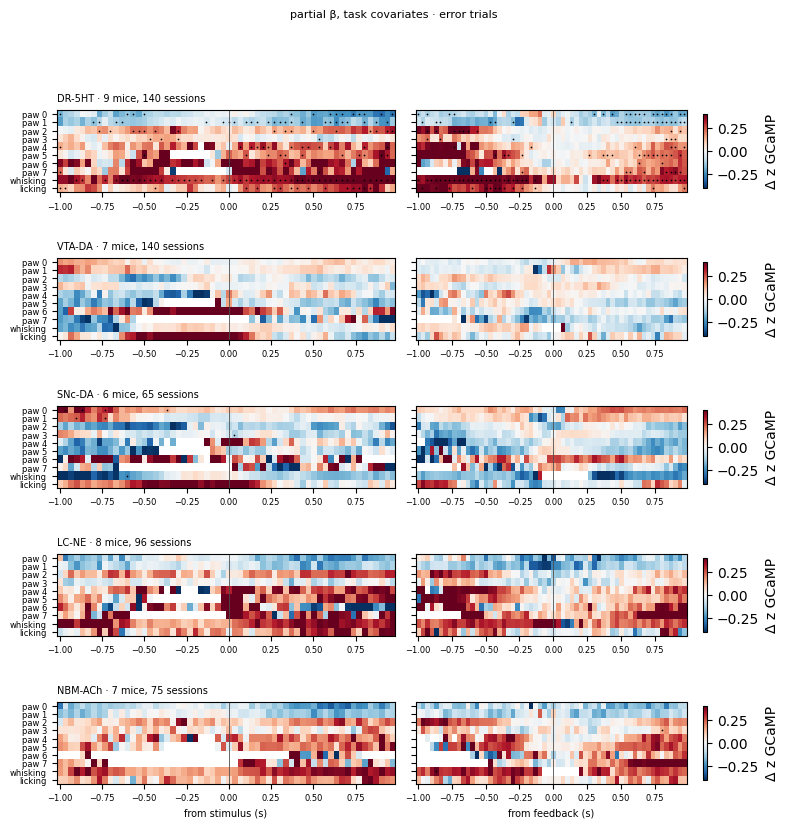

In [11]:
EFF = {k: pd.read_pickle(CACHE / f'effects_{k}_{ns.RUN}.pkl') for k in ('task', 'extended')}
JOINT = pd.read_pickle(CACHE / f'joint_{ns.RUN}.pkl')
VAR = pd.read_pickle(CACHE / f'variance_{ns.RUN}.pkl')
NAMES = EFF['task'].attrs['features']
print({k: len(v) for k, v in {**EFF, 'joint': JOINT, 'variance': VAR}.items()}, 'fiber-session × outcome rows')

def mice_maps(table, col, outcome, lim, title):
    # one row per NM: stimulus | feedback map of the mouse-mean, dots where q < .05
    fig = plt.figure(figsize=(9, 1.75 * len(NM_ORDER)))
    gs = fig.add_gridspec(len(NM_ORDER), 1, hspace=0.8)
    S = {w: ns.summarise(table, f'{col}_{w}') for w in ns.WINDOWS}
    h = (TIME[1] - TIME[0]) / 2
    for i, nm in enumerate(NM_ORDER):
        sub = gs[i].subgridspec(1, 2, wspace=0.06)
        for k, w in enumerate(ns.WINDOWS):
            s = S[w][(nm, outcome)]
            ax = fig.add_subplot(sub[k])
            im = ax.imshow(s['mean'], aspect='auto', cmap='RdBu_r', vmin=-lim, vmax=lim, interpolation='nearest',
                           extent=(TIME[0] - h, TIME[-1] + h, len(NAMES) - 0.5, -0.5))
            yy, xx = np.nonzero(s['q'] < 0.05)
            ax.scatter(TIME[xx], yy, s=1.5, color='k', lw=0)
            ax.axvline(0, color='0.3', lw=0.6)
            ax.set_yticks(range(len(NAMES)), NAMES if k == 0 else [], fontsize=6)
            ax.tick_params(labelsize=6)
            if i == len(NM_ORDER) - 1:
                ax.set_xlabel(['from stimulus (s)', 'from feedback (s)'][k], fontsize=7)
            if k == 0:
                ax.set_title(f"{nm} · {s['n_mice']} mice, {s['n_sessions']} sessions", fontsize=7, loc='left')
        fig.colorbar(im, ax=ax, shrink=0.9, label='Δ z GCaMP')
    fig.suptitle(title, fontsize=8, y=0.995)
    plt.show()

mice_maps(EFF['task'], 'beta', 1., 0.4, 'partial β, task covariates · rewarded trials')
mice_maps(EFF['task'], 'beta', 0., 0.4, 'partial β, task covariates · error trials')

### 4b. One number per epoch

β averaged over three epochs (pre-stimulus −0.5–0 s, post-stimulus 0–0.5 s, post-feedback 0–1 s), for the base-rate-free Δz, the partial β with task or extended covariates, and the joint β (all features in one model, paw states against paw 0). Each cell: mouse mean, then how many mice share its sign; * p < .05, ** p < .01 in a t-test across mice. Paw 7 is too rare before the stimulus in most mice to estimate.

In [12]:
EPOCHS = {'pre-stim': ('stim', (TIME >= -0.5) & (TIME < 0)), 'post-stim': ('stim', (TIME >= 0) & (TIME < 0.5)),
          'post-fb': ('fb', (TIME >= 0) & (TIME < 1))}
SHOW = ['paw 0', 'paw 7', 'whisking', 'licking']

def epoch_means(table, col):
    # one row per (mouse, NM, outcome, epoch, feature): the mouse's mean over sessions and the epoch's samples
    rows = []
    for _, r in table.iterrows():
        for ep, (w, m) in EPOCHS.items():
            for f, v in zip(NAMES, np.nanmean(r[f'{col}_{w}'][:, m], 1)):
                rows.append((r['target_NM'], r['outcome'], r['subject'], ep, f, v))
    d = pd.DataFrame(rows, columns=['nm', 'outcome', 'subject', 'epoch', 'feature', 'v'])
    return d.groupby(['nm', 'outcome', 'epoch', 'feature', 'subject'])['v'].mean().reset_index()

def epoch_table(table, col, outcome):
    from scipy.stats import ttest_1samp
    d = epoch_means(table, col).query('outcome == @outcome and feature in @SHOW')
    def cell(x):
        x = x.dropna()
        if len(x) < 3:
            return f'{x.mean():+.2f} (n={len(x)})' if len(x) else ''
        p = ttest_1samp(x, 0).pvalue
        return f"{x.mean():+.2f} {int((np.sign(x) == np.sign(x.mean())).sum())}/{len(x)}" + '*' * int((p < .05) + (p < .01))
    t = d.groupby(['nm', 'feature', 'epoch'])['v'].apply(cell).unstack('epoch')[list(EPOCHS)]
    return t.reindex(pd.MultiIndex.from_product([NM_ORDER, SHOW], names=['nm', 'feature']))

for o, label in [(1., 'rewarded'), (0., 'error')]:
    print(f'\n=== {label} trials')
    print(pd.concat({'Δz': epoch_table(EFF['task'], 'dz', o), 'β task': epoch_table(EFF['task'], 'beta', o),
                     'β extended': epoch_table(EFF['extended'], 'beta', o), 'β joint': epoch_table(JOINT, 'beta', o)},
                    axis=1).to_string())


=== rewarded trials


                           Δz                               β task                           β extended                              β joint                        
epoch                pre-stim   post-stim     post-fb     pre-stim   post-stim     post-fb     pre-stim   post-stim     post-fb     pre-stim   post-stim     post-fb
nm      feature                                                                                                                                                     
DR-5HT  paw 0       -0.06 5/9  -0.12 9/9*   -0.08 6/9   -0.10 8/9*   -0.05 6/9   -0.06 6/9   -0.11 8/9*   -0.05 7/9   -0.05 6/9                                     
        paw 7       +0.17 2/3  +0.24 8/9*   +0.03 6/9    +0.18 3/3  +0.14 7/9*   +0.03 6/9    +0.04 2/3  +0.15 7/9*   +0.04 6/9    +0.09 2/3  +0.15 8/9*   -0.01 4/9
        whisking   +0.27 9/9*  +0.34 9/9*  +0.22 7/9*   +0.26 9/9*  +0.31 9/9*   +0.20 6/9   +0.27 9/9*  +0.30 9/9*   +0.20 6/9   +0.25 9/9*  +0.26 9/9*   +0.21 7/9
        li

                           Δz                               β task                           β extended                              β joint                        
epoch                pre-stim   post-stim     post-fb     pre-stim   post-stim     post-fb     pre-stim   post-stim     post-fb     pre-stim   post-stim     post-fb
nm      feature                                                                                                                                                     
DR-5HT  paw 0       -0.04 6/9  -0.11 9/9*  -0.17 9/9*   -0.08 7/9*  -0.09 9/9*  -0.17 9/9*   -0.08 7/9*  -0.09 8/9*  -0.17 9/9*                                     
        paw 7     +0.62 (n=2)  +0.37 6/7*  +0.11 7/9*  +0.71 (n=2)   +0.28 5/7   +0.10 7/9  +0.74 (n=2)   +0.28 5/7   +0.09 7/9  +0.57 (n=2)   +0.26 6/7   +0.12 8/9
        whisking   +0.29 9/9*  +0.34 9/9*  +0.30 9/9*   +0.28 9/9*  +0.34 9/9*  +0.30 9/9*   +0.29 9/9*  +0.34 9/9*  +0.28 9/9*   +0.27 9/9*  +0.30 9/9*  +0.23 9/9*
        li

### 4c. Syllables add nothing beyond continuous vigor

Cross-validated R² per sample, averaged over each epoch, then over each mouse's sessions, then over mice. "Movement" = R²(all) − R²(task variables): everything the movement measures explain together. It is split into the unique vigor part, the unique syllable part and the part they share.

The unique syllable share is ~0 everywhere: what the syllables carry about the photometry, the continuous vigor signals carry too. From here on, movement = vigor only.

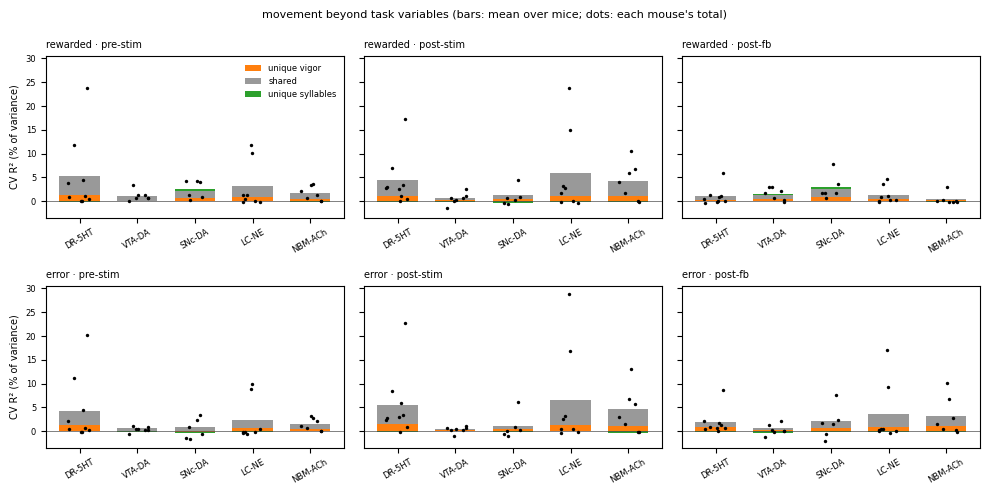

task variables      movement      unique vigor      shared  \
outcome                      0.0  1.0      0.0  1.0          0.0  1.0    0.0   
epoch     nm                                                                   
post-fb   DR-5HT            -1.4  2.4      1.8  1.0          0.8  0.3    1.1   
          LC-NE             -0.8  6.4      3.4  1.3          0.9  0.4    2.6   
          NBM-ACh           -1.2  1.2      3.1  0.4          1.0  0.2    2.2   
          SNc-DA             0.2  5.0      1.8  2.9          0.6  0.9    1.4   
          VTA-DA             2.1  6.5      0.3  1.5          0.3  0.4    0.4   
post-stim DR-5HT            -1.9  1.6      5.5  4.2          1.4  1.1    4.1   
          LC-NE             -0.7  2.6      6.5  5.7          1.3  1.2    5.2   
          NBM-ACh           -1.7  1.0      4.3  4.1          1.0  1.1    3.5   
          SNc-DA            -2.3  7.3      0.9  0.9          0.4  0.5    0.6   
          VTA-DA            -0.6  3.1      0.4  0.5          0.3  0.3    0.0   
pre-stim  DR-5HT            -1.7 -0.1      4.3  5.1          1.4  1.3    2.9   
          LC-NE             -1.3  1.6      2.2  3.1          0.7  0.8    1.6   
          NBM-ACh           -1.1  0.4      1.4  1.6          0.4  0.5    1.0   
          SNc-DA            -2.2 -0.2      0.5  2.5         -0.3  0.6    0.9   
          VTA-DA            -1.7 -0.1      0.4  1.1         -0.0  0.0    0.6   

                       unique syllables       
outcome            1.0              0.0  1.0  
epoch     nm                                  
post-fb   DR-5HT   0.7             -0.1 -0.0  
          LC-NE    0.9             -0.1  0.0  
          NBM-ACh  0.3             -0.1 -0.1  
          SNc-DA   1.6             -0.3  0.4  
          VTA-DA   0.9             -0.4  0.2  
post-stim DR-5HT   3.4             -0.1 -0.3  
          LC-NE    4.7             -0.0 -0.1  
          NBM-ACh  3.2             -0.3 -0.2  
          SNc-DA   0.7             -0.1 -0.3  
          VTA-DA   0.5             -0.0 -0.2  
pre-stim  DR-5HT   3.9              0.0 -0.1  
          LC-NE    2.3             -0.1 -0.0  
          NBM-ACh  1.2             -0.0 -0.1  
          SNc-DA   1.5             -0.2  0.3  
          VTA-DA   1.0             -0.2  0.1

In [13]:
rows = []
for _, r in VAR.iterrows():
    for ep, (w, m) in EPOCHS.items():
        R = np.nanmean(r[f'r2_{w}'][:, m], 1)
        rows.append({'nm': r['target_NM'], 'outcome': r['outcome'], 'subject': r['subject'], 'epoch': ep,
                     'task variables': R[0], 'movement': R[3] - R[0], 'unique vigor': R[3] - R[2],
                     'unique syllables': R[3] - R[1]})
vp = pd.DataFrame(rows).groupby(['nm', 'outcome', 'epoch', 'subject']).mean().reset_index()
vp['shared'] = vp['movement'] - vp['unique vigor'] - vp['unique syllables']

PARTS = [('unique vigor', 'C1'), ('shared', '0.6'), ('unique syllables', 'C2')]
fig, axes = plt.subplots(2, 3, figsize=(10, 5), sharey=True)
for i, (o, label) in enumerate([(1., 'rewarded'), (0., 'error')]):
    for k, ep in enumerate(EPOCHS):
        ax = axes[i, k]
        g = vp.query('outcome == @o and epoch == @ep').groupby('nm')
        for j, nm in enumerate(NM_ORDER):
            d = g.get_group(nm)
            pos = neg = 0.
            for part, c in PARTS:
                v = d[part].mean() * 100
                ax.bar(j, v, bottom=pos if v >= 0 else neg, color=c, width=0.7, label=part if j == 0 else None)
                pos, neg = (pos + v, neg) if v >= 0 else (pos, neg + v)
            ax.scatter(np.full(len(d), j) + np.random.default_rng(j).uniform(-0.2, 0.2, len(d)), d['movement'] * 100,
                       s=6, color='k', zorder=3, lw=0)
        ax.axhline(0, color='0.3', lw=0.5)
        ax.set_xticks(range(len(NM_ORDER)), NM_ORDER, fontsize=6, rotation=30)
        ax.tick_params(labelsize=6)
        ax.set_title(f'{label} · {ep}', fontsize=7, loc='left')
    axes[i, 0].set_ylabel('CV R² (% of variance)', fontsize=7)
axes[0, 0].legend(fontsize=6, frameon=False)
fig.suptitle('movement beyond task variables (bars: mean over mice; dots: each mouse\'s total)', fontsize=8)
plt.tight_layout(); plt.show()

(vp.groupby(['outcome', 'epoch', 'nm'])[['task variables', 'movement', 'unique vigor', 'shared', 'unique syllables']]
   .mean().mul(100).round(1).unstack('outcome'))

#### Over time: task variables vs vigor

Time-resolved version of 4d (below), outcomes pooled, task = the full set including outcome, movement = vigor only. Each mouse's sessions are averaged per sample; the line is the mean over mice, shaded ± s.e.m. across mice. Left pair: CV R² of task variables, vigor and both. Right pair: what each adds beyond the other. A sample needs ≥ 60 trials in a session to be fitted.

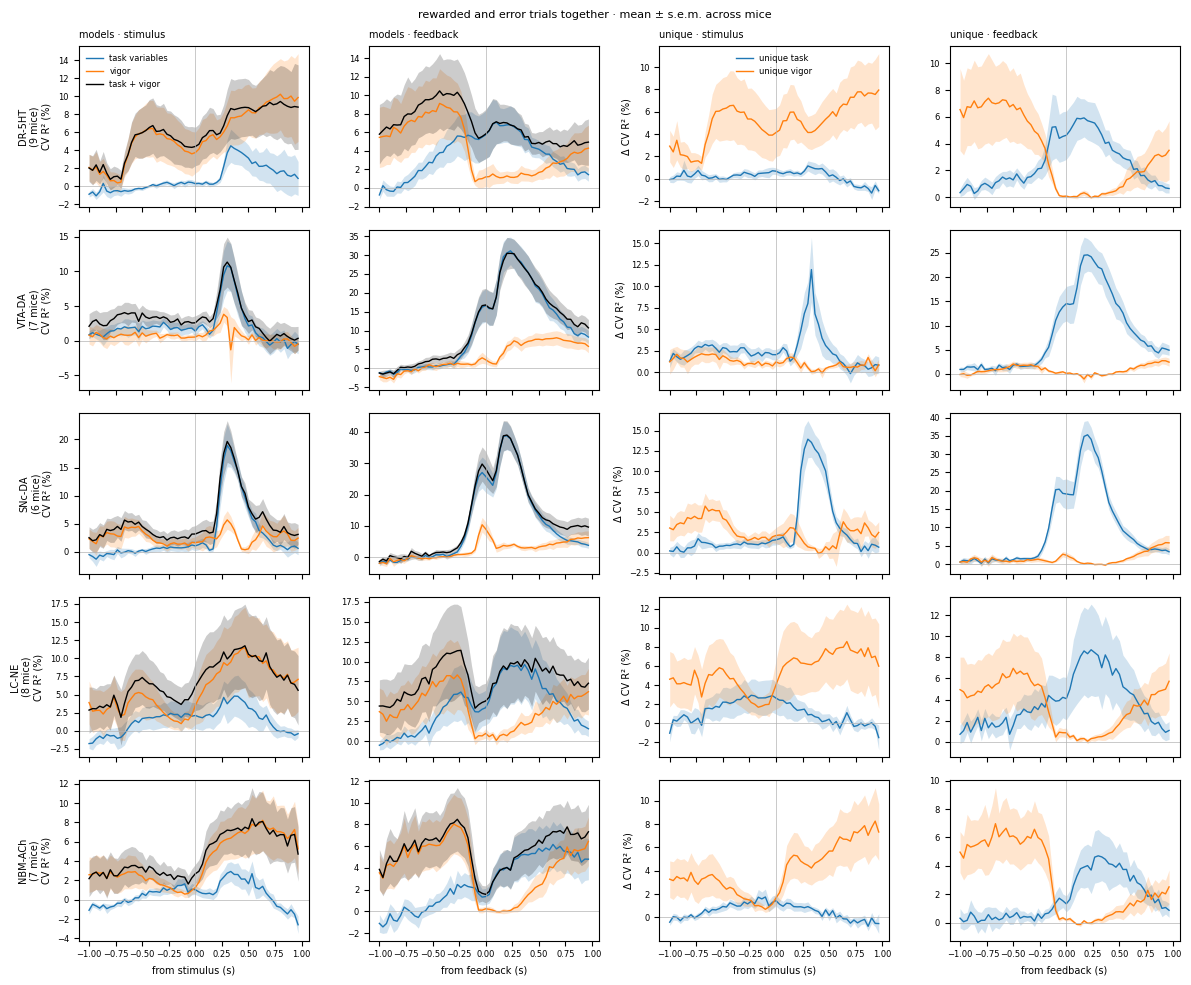

In [14]:
TVV = pd.read_pickle(CACHE / f'task_vs_vigor_{ns.RUN}.pkl')

def r2_over_time(table):
    fig, axes = plt.subplots(len(NM_ORDER), 4, figsize=(12, 2 * len(NM_ORDER)), sharex='col')
    for i, nm in enumerate(NM_ORDER):
        g = table.query('target_NM == @nm')
        for k, w in enumerate(ns.WINDOWS):
            # mice x models x T
            mice = np.stack([np.nanmean(np.stack(gm[f'r2_{w}'].to_list()), 0) for _, gm in g.groupby('subject')]) * 100
            models = [('task variables', mice[:, 0], 'C0'), ('vigor', mice[:, 1], 'C1'), ('task + vigor', mice[:, 2], 'k')]
            unique = [('unique task', mice[:, 2] - mice[:, 1], 'C0'), ('unique vigor', mice[:, 2] - mice[:, 0], 'C1')]
            for ax, lines in [(axes[i, k], models), (axes[i, 2 + k], unique)]:
                for label, y, c in lines:
                    n = (~np.isnan(y)).sum(0)
                    mu, se = np.nanmean(y, 0), np.nanstd(y, 0) / np.sqrt(np.maximum(n - 1, 1))
                    ax.plot(TIME, mu, color=c, lw=1, label=label)
                    ax.fill_between(TIME, mu - se, mu + se, color=c, alpha=0.2, lw=0)
                ax.axhline(0, color='0.7', lw=0.5); ax.axvline(0, color='0.7', lw=0.5); ax.tick_params(labelsize=6)
        axes[i, 0].set_ylabel(f'{nm}\n({len(mice)} mice)\nCV R² (%)', fontsize=7)
        axes[i, 2].set_ylabel('Δ CV R² (%)', fontsize=7)
    for k, lab in enumerate(['from stimulus (s)', 'from feedback (s)'] * 2):
        axes[-1, k].set_xlabel(lab, fontsize=7)
    for k, t in enumerate(['models · stimulus', 'models · feedback', 'unique · stimulus', 'unique · feedback']):
        axes[0, k].set_title(t, fontsize=7, loc='left')
    axes[0, 0].legend(fontsize=6, frameon=False); axes[0, 2].legend(fontsize=6, frameon=False)
    fig.suptitle('rewarded and error trials together · mean ± s.e.m. across mice', fontsize=8)
    plt.tight_layout(); plt.show()

r2_over_time(TVV)

#### Over time, unfolded into components

The right-hand pair above, split up: each line is what one task variable (left pair) or one vigor signal (right pair) adds when everything else is already in the model, R²(task + vigor) − R²(task + vigor without it). Unique shares don't sum to the totals above: what two components share is in neither.

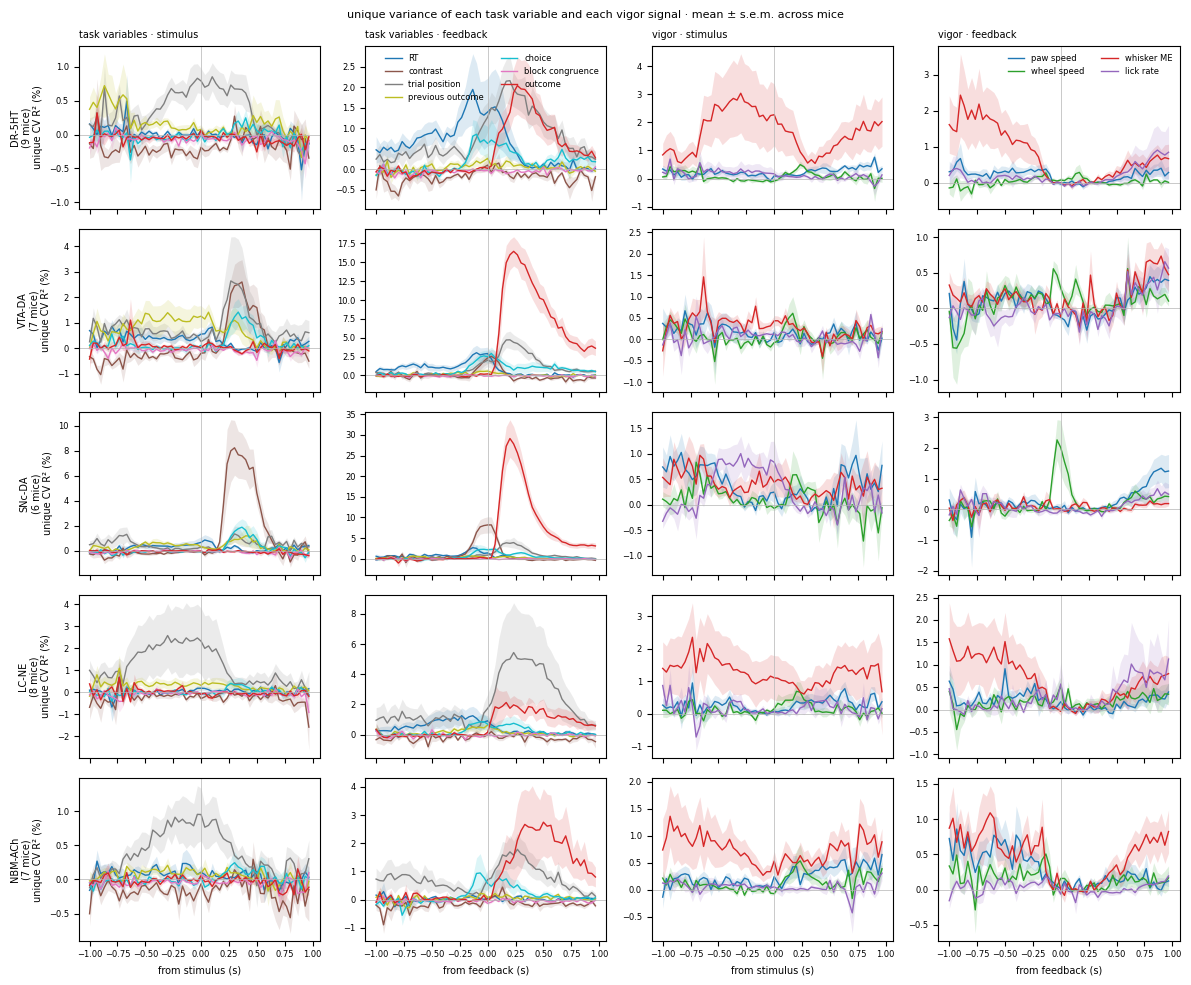

In [15]:
TASK_COLORS = dict(zip(TVV.attrs['groups'], ['C0', 'C5', 'C7', 'C8', 'C9', 'C6', 'C3']))
VIGOR_COLORS = dict(zip(TVV.attrs['parts'], ['C0', 'C2', 'C3', 'C4']))

def unfolded_over_time(table):
    G, V, M = table.attrs['groups'], table.attrs['parts'], table.attrs['models']
    fig, axes = plt.subplots(len(NM_ORDER), 4, figsize=(12, 2 * len(NM_ORDER)), sharex='col')
    for i, nm in enumerate(NM_ORDER):
        g = table.query('target_NM == @nm')
        for k, w in enumerate(ns.WINDOWS):
            mice = np.stack([np.nanmean(np.stack(gm[f'r2_{w}'].to_list()), 0) for _, gm in g.groupby('subject')]) * 100
            for col, names, colors in [(k, G, TASK_COLORS), (2 + k, V, VIGOR_COLORS)]:
                ax = axes[i, col]
                for name in names:
                    y = mice[:, 2] - mice[:, M.index(f'without {name}')]
                    n = (~np.isnan(y)).sum(0)
                    mu, se = np.nanmean(y, 0), np.nanstd(y, 0) / np.sqrt(np.maximum(n - 1, 1))
                    ax.plot(TIME, mu, color=colors[name], lw=1, label=name)
                    ax.fill_between(TIME, mu - se, mu + se, color=colors[name], alpha=0.15, lw=0)
                ax.axhline(0, color='0.7', lw=0.5); ax.axvline(0, color='0.7', lw=0.5); ax.tick_params(labelsize=6)
        axes[i, 0].set_ylabel(f'{nm}\n({len(mice)} mice)\nunique CV R² (%)', fontsize=7)
    for k, lab in enumerate(['from stimulus (s)', 'from feedback (s)'] * 2):
        axes[-1, k].set_xlabel(lab, fontsize=7)
    for k, t in enumerate(['task variables · stimulus', 'task variables · feedback', 'vigor · stimulus', 'vigor · feedback']):
        axes[0, k].set_title(t, fontsize=7, loc='left')
    axes[0, 1].legend(fontsize=6, frameon=False, ncol=2); axes[0, 3].legend(fontsize=6, frameon=False, ncol=2)
    fig.suptitle('unique variance of each task variable and each vigor signal · mean ± s.e.m. across mice', fontsize=8)
    plt.tight_layout(); plt.show()

unfolded_over_time(TVV)

### 4d. Vigor vs task variables, per epoch

Same cross-validated ridge, now with rewarded and error trials together, so the outcome can be a task variable (`ns.task_vs_movement`). **Task** = log response RT, |contrast| level, trial position (+ ²), previous outcome, choice side, block congruence and outcome. **Vigor** = log(1 + ·) of paw speed, wheel speed, whisker ME and lick rate (syllables dropped, see 4c). Unique task = R²(both) − R²(vigor), unique vigor = R²(both) − R²(task); the rest is shared. Each task variable's own unique share is R²(both) − R²(both without it).

This is variance across trials at a fixed sample, so the mean time course (PSTH) is not in it. The second table shows how much of the total variance (trials × samples in the epoch) the PSTH, and the PSTH split by outcome, take on their own.

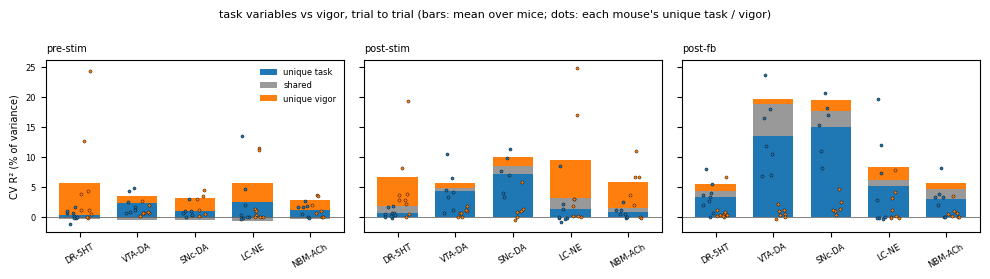

/tmp/ipykernel_133656/359257818.py:37: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary['mice vigor > task'] = tvm.groupby(['epoch', 'nm']).apply(
/tmp/ipykernel_133656/359257818.py:39: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary['p (Wilcoxon)'] = tvm.groupby(['epoch', 'nm']).apply(


task  vigor  both  unique task  shared  unique vigor   RT  \
pre-stim  DR-5HT    0.2    5.2   5.6          0.4    -0.2           5.4  0.0   
          VTA-DA    1.9    0.7   3.1          2.4    -0.5           1.2  0.4   
          SNc-DA    0.7    1.8   2.9          1.1    -0.4           2.2  0.4   
          LC-NE     2.0    2.7   5.3          2.6    -0.5           3.2  0.0   
          NBM-ACh   1.0    1.4   2.6          1.2    -0.2           1.6  0.1   
post-stim DR-5HT    1.9    6.1   6.8          0.7     1.2           4.9 -0.0   
          VTA-DA    5.0    1.4   5.8          4.5     0.5           0.8  0.2   
          SNc-DA    8.5    2.7  10.0          7.3     1.2           1.5  0.3   
          LC-NE     3.2    8.1   9.5          1.4     1.8           6.3  0.1   
          NBM-ACh   1.6    5.1   6.0          0.9     0.8           4.3  0.1   
post-fb   DR-5HT    4.3    2.2   5.5          3.3     1.0           1.2  0.4   
          VTA-DA   18.8    6.1  19.6         13.5     5.3           0.8  0.3   
          SNc-DA   17.6    4.5  19.6         15.1     2.6           2.0  0.2   
          LC-NE     6.3    3.2   8.4          5.2     1.1           2.1  0.2   
          NBM-ACh   4.7    2.6   5.7          3.0     1.7           0.9  0.0   

                   contrast  trial position  previous outcome  choice  \
pre-stim  DR-5HT       -0.2             0.5               0.1    -0.0   
          VTA-DA       -0.3             0.6               1.2     0.0   
          SNc-DA       -0.1             0.2               0.6    -0.1   
          LC-NE        -0.1             2.3               0.4    -0.0   
          NBM-ACh      -0.2             0.8               0.1    -0.0   
post-stim DR-5HT       -0.1             0.7               0.1     0.1   
          VTA-DA        1.1             1.4               0.8     0.6   
          SNc-DA        4.2             0.6               0.6     0.7   
          LC-NE        -0.2             1.1               0.3     0.1   
          NBM-ACh      -0.1             0.5               0.1     0.1   
post-fb   DR-5HT       -0.2             1.2               0.1     0.3   
          VTA-DA       -0.0             2.0               0.0     1.1   
          SNc-DA        0.8             1.4               0.1     0.7   
          LC-NE        -0.2             3.2               0.1     0.3   
          NBM-ACh      -0.1             0.9               0.1     0.3   

                   block congruence  outcome  paw speed  wheel speed  \
pre-stim  DR-5HT               -0.1     -0.0        0.1         -0.1   
          VTA-DA               -0.1      0.1        0.1         -0.0   
          SNc-DA               -0.0     -0.0        0.2          0.1   
          LC-NE                -0.0      0.1        0.2          0.0   
          NBM-ACh              -0.0      0.0        0.1          0.0   
post-stim DR-5HT               -0.1     -0.0        0.2          0.2   
          VTA-DA               -0.1      0.0        0.0          0.1   
          SNc-DA               -0.1     -0.0        0.1          0.2   
          LC-NE                -0.0     -0.1        0.3          0.3   
          NBM-ACh              -0.0     -0.0        0.3          0.2   
post-fb   DR-5HT               -0.0      0.9        0.1          0.1   
          VTA-DA               -0.0      8.1        0.1          0.1   
          SNc-DA               -0.1     10.1        0.4          0.3   
          LC-NE                -0.0      1.3        0.1          0.2   
          NBM-ACh              -0.1      1.7        0.1          0.1   

                   whisker ME  lick rate mice vigor > task  p (Wilcoxon)  
pre-stim  DR-5HT          2.6        0.2               6/9         0.098  
          VTA-DA          0.4        0.1               2/7         0.109  
          SNc-DA          0.4        0.8               6/6         0.031  
          LC-NE           1.3        0.1               5/8         0.383  
          NBM-ACh         0.6        0.1 

In [16]:
TVM = TVV
G, PARTS_V = TVM.attrs['groups'], TVM.attrs['parts']
rows = []
for _, r in TVM.iterrows():
    for ep, (w, m) in EPOCHS.items():
        R = np.nanmean(r[f'r2_{w}'][:, m], 1)
        rows.append({'nm': r['target_NM'], 'subject': r['subject'], 'epoch': ep, 'task': R[0], 'vigor': R[1],
                     'both': R[2], 'unique task': R[2] - R[1], 'unique vigor': R[2] - R[0],
                     **{g: R[2] - R[3 + k] for k, g in enumerate(G)},
                     **{v: R[2] - R[3 + len(G) + k] for k, v in enumerate(PARTS_V)}})
tvm = pd.DataFrame(rows).groupby(['nm', 'epoch', 'subject']).mean().reset_index()
tvm['shared'] = tvm['both'] - tvm['unique task'] - tvm['unique vigor']

PARTS = [('unique task', 'C0'), ('shared', '0.6'), ('unique vigor', 'C1')]
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
for ax, ep in zip(axes, EPOCHS):
    g = tvm.query('epoch == @ep').groupby('nm')
    for j, nm in enumerate(NM_ORDER):
        d = g.get_group(nm)
        pos = neg = 0.
        for part, c in PARTS:
            v = d[part].mean() * 100
            ax.bar(j, v, bottom=pos if v >= 0 else neg, color=c, width=0.7, label=part if j == 0 else None)
            pos, neg = (pos + v, neg) if v >= 0 else (pos, neg + v)
        jit = np.random.default_rng(j).uniform(-0.25, 0.25, len(d))
        ax.scatter(j - 0.12 + jit * 0.4, d['unique task'] * 100, s=5, color='C0', ec='k', lw=0.3, zorder=3)
        ax.scatter(j + 0.12 + jit * 0.4, d['unique vigor'] * 100, s=5, color='C1', ec='k', lw=0.3, zorder=3)
    ax.axhline(0, color='0.3', lw=0.5)
    ax.set_xticks(range(len(NM_ORDER)), NM_ORDER, fontsize=6, rotation=30); ax.tick_params(labelsize=6)
    ax.set_title(ep, fontsize=7, loc='left')
axes[0].set_ylabel('CV R² (% of variance)', fontsize=7); axes[0].legend(fontsize=6, frameon=False)
fig.suptitle('task variables vs vigor, trial to trial (bars: mean over mice; dots: each mouse\'s unique task / vigor)', fontsize=8)
plt.tight_layout(); plt.show()

from scipy.stats import wilcoxon
summary = tvm.groupby(['epoch', 'nm'])[['task', 'vigor', 'both', 'unique task', 'shared', 'unique vigor'] + G + PARTS_V].mean().mul(100).round(1)
summary['mice vigor > task'] = tvm.groupby(['epoch', 'nm']).apply(
    lambda x: f"{(x['unique vigor'] > x['unique task']).sum()}/{len(x)}")
summary['p (Wilcoxon)'] = tvm.groupby(['epoch', 'nm']).apply(
    lambda x: wilcoxon(x['unique vigor'] - x['unique task']).pvalue).round(3)
summary.reindex(pd.MultiIndex.from_product([list(EPOCHS), NM_ORDER]))

In [17]:
def psth_share(eid):
    # fraction of all variance (trials x samples in the epoch) taken by the PSTH, and by the PSTH per outcome
    out = []
    for f in ns.load_session(eid, movement=False):
        m = f['meta']
        for ep, (w, msk) in EPOCHS.items():
            P = f[w]['photometry'][:, msk]
            by_outcome = P.copy()
            for o in (0, 1):
                r = (m['correct'] == o).to_numpy()
                by_outcome[r] = P[r] - np.nanmean(P[r], 0)
            out.append({'nm': m['target_NM'].iat[0], 'subject': m['subject'].iat[0], 'epoch': ep,
                        'PSTH': 1 - np.nanvar(P - np.nanmean(P, 0)) / np.nanvar(P),
                        'PSTH by outcome': 1 - np.nanvar(by_outcome) / np.nanvar(P)})
    return out

psth = pd.DataFrame([r for eid in rec['eid'].unique() for r in psth_share(eid)])
(psth.groupby(['epoch', 'nm', 'subject']).mean().groupby(['epoch', 'nm']).mean().mul(100).round(1)
     .reindex(pd.MultiIndex.from_product([list(EPOCHS), NM_ORDER])))

PSTH  PSTH by outcome
pre-stim  DR-5HT    0.7              0.9
          VTA-DA    0.3              0.7
          SNc-DA    0.4              0.7
          LC-NE     1.3              1.6
          NBM-ACh   0.6              0.9
post-stim DR-5HT    1.9              2.4
          VTA-DA   11.3             11.9
          SNc-DA   16.8             18.1
          LC-NE     3.5              4.0
          NBM-ACh   2.8              3.1
post-fb   DR-5HT    4.3              6.8
          VTA-DA    4.7             20.0
          SNc-DA    8.6             23.0
          LC-NE     8.6             11.3
          NBM-ACh   3.1              6.9

## 5. Trial position: engagement or something else?

Trial position (the trial's place in the session, 0 → 1, plus its square) explains a consistent share of the signal in 4d. Run `python neuromodulators/trial_position_engagement.py glmhmm` then `... fit` first (code and method in the script's docstring). Three questions:

- **Shape.** Per sample, the OLS β of session time (z-scored within the session, task variables held fixed). A technical additive drift would give a flat β(t). A loss of gain (sensor, or smaller responses from satiety) would give β(t) proportional to the mean response (PSTH), with a negative slope.
- **Engagement.** P(engaged) per trial from the paper's K = 2 GLM-HMM, fitted per mouse on the export's sessions (no-go trials masked). Does it add cross-validated R² to the task variables, and does it still add once a smooth function of session time (cubic B-spline, 5 df) is in?
- **Clocks.** Session time (bleaching, light exposure), trial count, cumulative reward (satiety). Within a session these correlate at r ≥ .99, so they can't be told apart here.

In [18]:
sys.path.insert(0, str(REPO / 'neuromodulators'))
import trial_position_engagement as tp
TPE = pd.read_pickle(tp.FIT_FILE)
POSTS = pd.read_parquet(tp.GLMHMM_FILE)
print(f"{len(TPE)} fibers; GLM-HMM posteriors for {POSTS['subject'].nunique()} mice, {POSTS['eid'].nunique()} sessions")
print('mean correlation between the clocks within a session:')
pd.DataFrame(np.nanmean(np.stack(TPE['r_clocks'].to_list()), 0), index=tp.CLOCKS, columns=tp.CLOCKS).round(3)

516 fibers; GLM-HMM posteriors for 36 mice, 489 sessions
mean correlation between the clocks within a session:


,session time,trial count,cumulative reward,p_engaged
session time,1.000,0.994,0.991,-0.174
trial count,0.994,1.000,0.999,-0.167
cumulative reward,0.991,0.999,1.000,-0.166
p_engaged,-0.174,-0.167,-0.166,1.000


### P(engaged) over the session

Each session's P(engaged), binned in tenths of the session, averaged per mouse; line = mean over mice ± s.e.m. Engagement falls over the session, so it *could* in principle carry the trial-position effect.

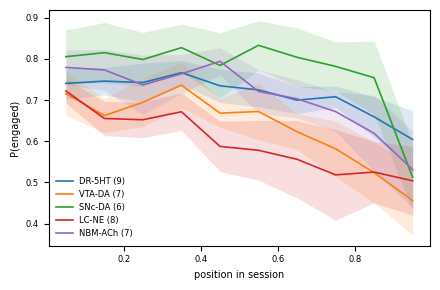

In [19]:
p = POSTS.merge(rec[['eid', 'target_NM']].drop_duplicates('eid'), on='eid')
p['frac'] = p.groupby('eid')['trial'].transform(lambda t: (t - t.min()) / (t.max() - t.min()))
p['bin'] = np.minimum((p['frac'] * 10).astype(int), 9)
traj = p.groupby(['target_NM', 'subject', 'bin'])['p_engaged'].mean().unstack('bin')
fig, ax = plt.subplots(figsize=(4.5, 3))
for k, nm in enumerate(NM_ORDER):
    y = traj.loc[nm].to_numpy()
    mu, se = y.mean(0), y.std(0) / np.sqrt(len(y) - 1)
    x = (np.arange(10) + 0.5) / 10
    ax.plot(x, mu, color=f'C{k}', lw=1.2, label=f'{nm} ({len(y)})')
    ax.fill_between(x, mu - se, mu + se, color=f'C{k}', alpha=0.15, lw=0)
ax.set_xlabel('position in session', fontsize=7); ax.set_ylabel('P(engaged)', fontsize=7)
ax.tick_params(labelsize=6); ax.legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()

### Shape: β of session time over the trial, against the mean response

Black: β(t) of session time (Δz per s.d. of session time, task variables held fixed), mean ± s.e.m. across mice. Grey dashed: the best fit a + b·PSTH(t) to that mean, where PSTH is the mice's mean response. A negative b means that over the session, each part of the response shrinks in proportion to its size. The numbers are the per-fiber fits (R² of the template, slope b), averaged per mouse, then over mice.

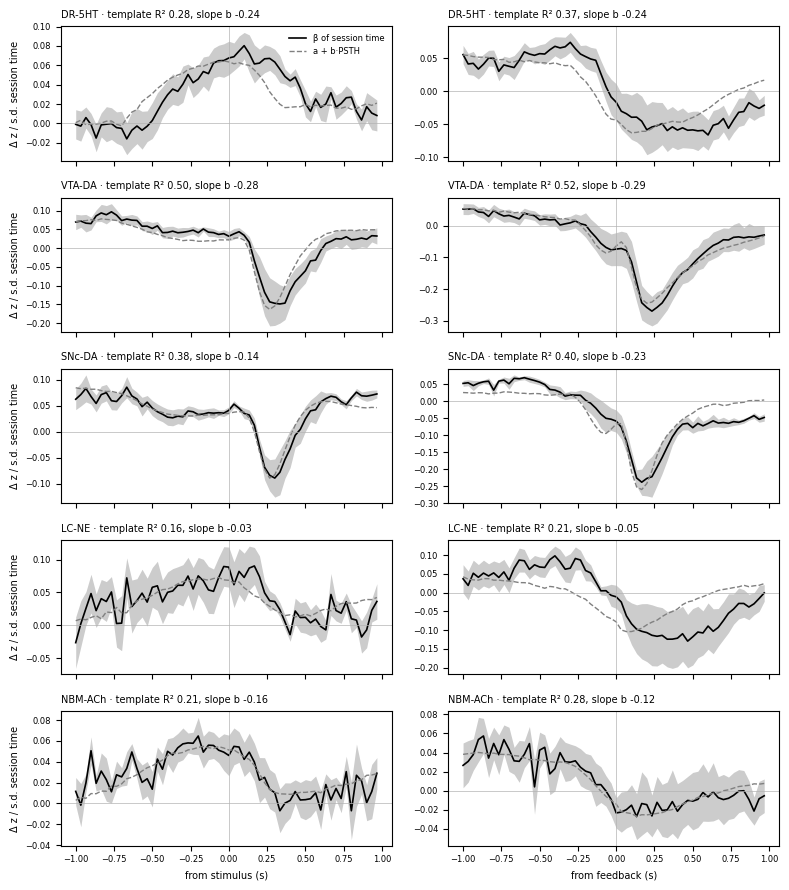

In [20]:
fig, axes = plt.subplots(len(NM_ORDER), 2, figsize=(8, 1.8 * len(NM_ORDER)), sharex='col')
for i, nm in enumerate(NM_ORDER):
    g = TPE[TPE['target_NM'] == nm]
    for k, w in enumerate(ns.WINDOWS):
        B = np.stack([np.nanmean(np.stack(gm[f'beta_{w}'].to_list()), 0) for _, gm in g.groupby('subject')])
        H = np.stack([np.nanmean(np.stack(gm[f'psth_{w}'].to_list()), 0) for _, gm in g.groupby('subject')])
        mu, se = np.nanmean(B, 0), np.nanstd(B, 0) / np.sqrt(len(B) - 1)
        ax = axes[i, k]
        ax.plot(TIME, mu, color='k', lw=1.2, label='β of session time')
        ax.fill_between(TIME, mu - se, mu + se, color='k', alpha=0.2, lw=0)
        h = np.nanmean(H, 0); ok = np.isfinite(mu) & np.isfinite(h)
        a, b = np.linalg.lstsq(np.column_stack([np.ones(ok.sum()), h[ok]]), mu[ok], rcond=None)[0]
        ax.plot(TIME, a + b * h, color='0.5', ls='--', lw=1, label='a + b·PSTH')
        fits = pd.DataFrame([tp.template_fit(r[f'beta_{w}'], r[f'psth_{w}'])[1:] + (r['subject'],)
                             for _, r in g.iterrows()], columns=['r2', 'b', 'subject']).groupby('subject').mean()
        ax.set_title(f"{nm} · template R² {fits['r2'].mean():.2f}, slope b {fits['b'].mean():+.2f}", fontsize=7, loc='left')
        ax.axhline(0, color='0.7', lw=0.5); ax.axvline(0, color='0.7', lw=0.5); ax.tick_params(labelsize=6)
    axes[i, 0].set_ylabel('Δ z / s.d. session time', fontsize=7)
axes[-1, 0].set_xlabel('from stimulus (s)', fontsize=7); axes[-1, 1].set_xlabel('from feedback (s)', fontsize=7)
axes[0, 0].legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()

### What each slow regressor adds, over time

CV R² added to the task variables by session time (blue) and by cumulative reward (orange, mostly hidden behind it: r ≥ .99), by P(engaged) on its own (green), and by P(engaged) once a smooth function of session time is already in (red). Mean ± s.e.m. across mice.

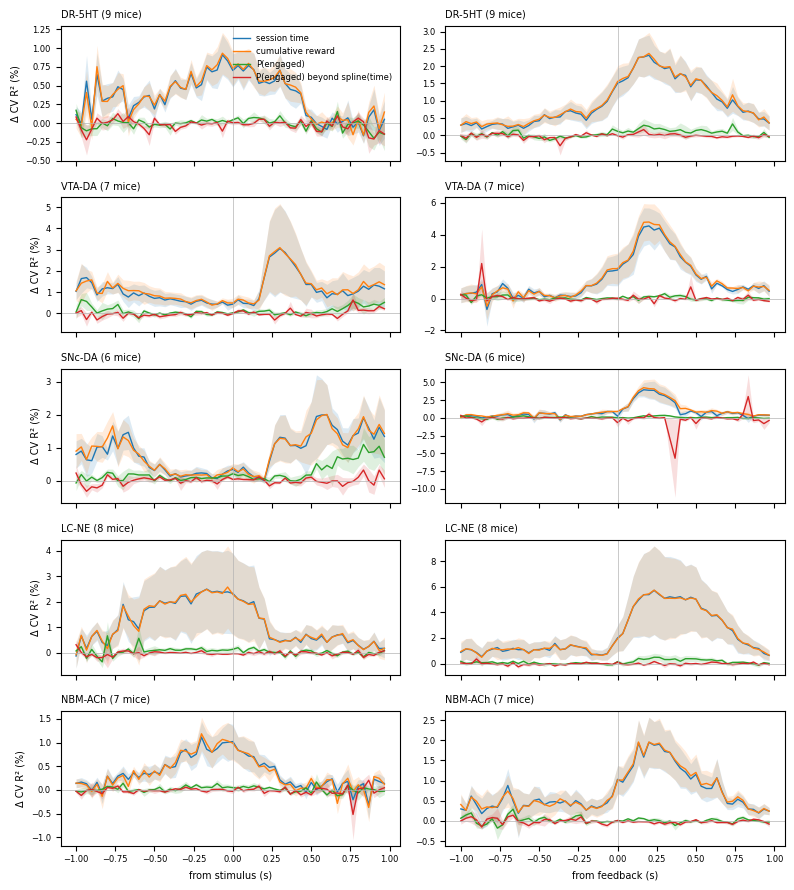

In [21]:
M = TPE.attrs['models']
LINES = [('session time', lambda R: R[M.index('task + session time')] - R[0], 'C0'),
         ('cumulative reward', lambda R: R[M.index('task + cumulative reward')] - R[0], 'C1'),
         ('P(engaged)', lambda R: R[M.index('task + p_engaged')] - R[0], 'C2'),
         ('P(engaged) beyond spline(time)', lambda R: R[-1] - R[-2], 'C3')]
fig, axes = plt.subplots(len(NM_ORDER), 2, figsize=(8, 1.8 * len(NM_ORDER)), sharex='col')
for i, nm in enumerate(NM_ORDER):
    g = TPE[TPE['target_NM'] == nm]
    for k, w in enumerate(ns.WINDOWS):
        mice = np.stack([np.nanmean(np.stack(gm[f'r2_{w}'].to_list()), 0) for _, gm in g.groupby('subject')]) * 100
        ax = axes[i, k]
        for label, f, c in LINES:
            y = np.stack([f(m) for m in mice])
            mu, se = np.nanmean(y, 0), np.nanstd(y, 0) / np.sqrt(len(y) - 1)
            ax.plot(TIME, mu, color=c, lw=1, label=label)
            ax.fill_between(TIME, mu - se, mu + se, color=c, alpha=0.15, lw=0)
        ax.axhline(0, color='0.7', lw=0.5); ax.axvline(0, color='0.7', lw=0.5); ax.tick_params(labelsize=6)
        ax.set_title(f'{nm} ({len(mice)} mice)', fontsize=7, loc='left')
    axes[i, 0].set_ylabel('Δ CV R² (%)', fontsize=7)
axes[-1, 0].set_xlabel('from stimulus (s)', fontsize=7); axes[-1, 1].set_xlabel('from feedback (s)', fontsize=7)
axes[0, 0].legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()

**Reading.** P(engaged) falls over the session but adds about nothing to the signal, either alone or beyond the time trend. The slow change is a rising baseline plus responses shrinking in proportion to their size (strongest for dopamine). That fits loss of sensor gain or satiety, not engagement. The three clocks can't be separated within a session. That needs the photometry QC (bleaching τ, isosbestic) or between-session comparisons.